# Nondirectional EEG–IBI covariation

Select **Python (dbh)** and run these **five steps** in order. The supplied data
cover 148 children. See the [setup instructions](../README.md#setup) for installation.

| Step | What it does | Result |
|---|---|---|
| 1 | Choose input paths and whether to use saved results or recompute | Run settings and one log |
| 2 | Check participant IDs, age groups, IBI and EEG file availability | Input summary |
| 3 | Correlate group-mean EEG and IBI time courses | 108 correlations and FDR-adjusted p values |
| 4 | Draw or display frontal correlations and alpha–IBI regression lines | Figure 2a and Figure 2b |
| 5 | Draw or display correlations across all three regions | Figure S2 |

**Inputs** — paths below are relative to the repository root:

| Data | Location |
|---|---|
| Participant IDs and ages | `00_data/participants.csv` |
| IBI time series | `01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz` |
| EEG band power | `01_preprocessing/outputs/manuscript/eeg/band_power/` |

**Outputs:** `results/Main/Figure_2a_eeg_ibi_correlations.png`,
`results/Main/Figure_2b_alpha_ibi_regression.png` and
`results/SI/Figure_S2_eeg_ibi_correlations.png`. Detailed tables and plotting inputs
are saved in this folder's `cache/`; each run writes one concise file in `logs/`.
The frontal results table and all three figures are also displayed below.


## 1. Choose paths and reuse/recompute mode

The defaults select the supplied 148-child data. Relative paths are resolved from
the repository root. When the prompt appears, type **1** or **2** and press Enter:

- **1 — use saved results (default):** read each complete saved step. The supplied
  `cache/` holds the results of the submitted analysis, so this reproduces the
  manuscript output; if any required file is missing or empty, that step is recomputed.
- **2 — recompute and replace:** rerun each analysis or plotting step you execute.
  Use this after changing inputs or analysis settings.

Pressing Enter alone selects 1. The choice applies to steps 3–5 for this run.
Rerunning step 1 lets you choose again and starts a new log; later steps append
to the current log. Use the full-cohort `ecg_ts.npz` for this analysis.


In [3]:
from importlib import import_module, reload
from pathlib import Path
import os
import sys

import matplotlib as mpl
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

override = os.environ.get("EEG_IBI_PROJECT_ROOT")
candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p.resolve() for p in candidates
     if (p / "03_correlation/config/correlation_config.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository, or set EEG_IBI_PROJECT_ROOT.")

COR = ROOT / "03_correlation"
INFO_FILE = ROOT / "00_data/participants.csv"
ECG_FILE = ROOT / "01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz"
EEG_DIR = ROOT / "01_preprocessing/outputs/manuscript/eeg/band_power"
OUTPUT_ROOT = Path(os.environ.get("EEG_IBI_OUTPUT_ROOT", str(COR)))

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RunLog = reload(import_module("common.run_log")).RunLog
cache_policy = reload(import_module("common.cache_policy"))
settings = reload(import_module("03_correlation.config.correlation_config"))
analysis = reload(import_module("03_correlation.analysis.analyze_eeg_ibi_correlations"))
figure_2 = reload(import_module("03_correlation.plotting.plot_figure_2_eeg_ibi_correlations"))
draw_figure_s2 = reload(import_module("03_correlation.plotting.plot_figure_s2_eeg_ibi_correlations")).plot_figure_s2

INFO_FILE, ECG_FILE, EEG_DIR, OUTPUT_ROOT = (
    settings.resolve_path(value, ROOT) for value in (INFO_FILE, ECG_FILE, EEG_DIR, OUTPUT_ROOT)
)
RESULT_DIR = OUTPUT_ROOT / "cache"
PUBLICATION_DIR = (ROOT if OUTPUT_ROOT == COR else OUTPUT_ROOT) / "results"
FIGURE_DIR = PUBLICATION_DIR / "Main"
SI_DIR = PUBLICATION_DIR / "SI"
ANALYSIS_OPTIONS = dict(
    root=ROOT, participants=INFO_FILE, ecg_file=ECG_FILE,
    eeg_dir=EEG_DIR, output_root=OUTPUT_ROOT,
)
LOG = RunLog(OUTPUT_ROOT / "logs", ROOT, title="EEG–IBI correlation", announce=False)
display(HTML('<style id="dbh-notebook-style">' +
             (ROOT / "common/notebook_style.css").read_text(encoding="utf-8") + "</style>"))

RECOMPUTE = cache_policy.choose_recompute()
UPDATED_FIGURES = set()
LOG.write("Run mode: recompute and replace" if RECOMPUTE else "Run mode: use complete cached results")
for heading, items in (("Inputs (read only)", [("Participants", INFO_FILE), ("IBI", ECG_FILE), ("EEG power", EEG_DIR)]),
                       ("Outputs", [("Analysis cache", RESULT_DIR), ("Main figures", FIGURE_DIR), ("SI figures", SI_DIR)])):
    print(heading)
    LOG.write(heading)
    for label, location in items:
        print(f"  {label:<20}{LOG.display(location)}")
        LOG.write(f"  {label:<20}{LOG.display(location)}")
print("Run log:", LOG.display(LOG.path))


1 = use complete saved results; compute missing or outdated steps (default)
2 = recompute and replace saved results and figures
Choose 2 after changing the input data or analysis settings.


Type 1 or 2, then press Enter (Enter alone = 1):  2


Inputs (read only)
  Participants        00_data/participants.csv
  IBI                 01_preprocessing/outputs/manuscript/ecg/hrv/ecg_ts.npz
  EEG power           01_preprocessing/outputs/manuscript/eeg/band_power
Outputs
  Analysis cache      03_correlation/cache
  Main figures        results/Main
  SI figures          results/SI
Run log: 03_correlation/logs/20261030_224122.log


## 2. Check and inspect the inputs

Check participant IDs, age groups, the 4-Hz IBI sampling grid and matching EEG
files for all 148 children. Missing or invalid inputs stop the analysis. Full EEG
channel, frequency and timestamp checks run when step 3 recomputes the correlations.

The table below shows the available inputs. `participants`, `ibi` (reduced to
1 Hz) and `eeg_files` remain available for inspection. Age groups are derived from
`Age_month`: 60–83, 84–107 and 108–131 months.


In [5]:
with LOG.step("Check inputs"):
    LOG.command([sys.executable, ROOT / "check_setup.py", "--python-only", "--quiet"])

    checked_inputs = analysis.run_analysis(**ANALYSIS_OPTIONS, check_only=True, print_tables=False)
    participants = checked_inputs["participants"]
    ibi = checked_inputs["ibi"]
    eeg_files = checked_inputs["eeg_files"]
    age_counts = participants.groupby("age_group", observed=True).size().reindex(settings.GROUPS)
    input_summary = pd.DataFrame([
        {"Input": "Participants", "Available": len(participants)},
        {"Input": "IBI (subjects × movies × 1-s bins)", "Available": str(ibi.shape)},
        {"Input": "EEG power files", "Available": len(eeg_files)},
        {"Input": "Age groups (5–6 / 7–8 / 9–10 years)",
         "Available": " / ".join(str(n) for n in age_counts)},
    ])
    display(input_summary.style.hide(axis="index"))
    LOG.write(f"Inputs passed: {len(participants)} participants, {len(eeg_files)} EEG files; age groups {age_counts.to_dict()}")


Python 3.12.7: /opt/anaconda3/envs/dbh/bin/python
[OK] numpy 2.2.6; scipy 1.16.3; pandas 2.3.3; matplotlib 3.10.8; sklearn 1.8.0; statsmodels 0.14.6; h5py 3.16.0; joblib 1.4.2; numba 0.61.2; llvmlite 0.44.0; tqdm 4.66.5; mne 1.11.0; neurokit2 0.2.13; IPython 9.17.1; ipykernel 6.28.0; jupyterlab 4.2.5; nbformat 5.10.4; tkinter available
Participants: 148 | Age groups: {'5-6': 50, '7-8': 49, '9-10': 49}
Valid IBI bins per child and movie: 157 to 176
Input check passed. Full EEG content checks run during analysis.


Input,Available
Participants,148
IBI (subjects × movies × 1-s bins),"(148, 3, 176)"
EEG power files,148
Age groups (5–6 / 7–8 / 9–10 years),50 / 49 / 49


## 3. Compute or load EEG–IBI correlations

Calculate **108 correlations**: 3 regions × 3 movies × 3 age groups × 4 EEG bands.
IBI is reduced from 4 Hz to 1 Hz by averaging finite samples in each block of four.
The 176 bins are paired by array position with EEG samples labelled 2–177 s.

Natural-log transform positive finite EEG power, then average channels within
each region. Average EEG and IBI separately over the available children in each
age group, without temporal interpolation. Correlate the two mean time courses,
requiring at least 60 valid time pairs and nonconstant signals.

Apply BH-FDR to **36 frontal tests** and, separately, **72 central/posterior tests**.
The ordinary two-sided Pearson p values do not adjust for temporal autocorrelation.

Display the 36 frontal tests below. `correlation_results` contains all 108 tests;
`group_timeseries` contains the mean curves used for plotting. The tables, input
summaries and calculation settings are saved in `cache/`.


In [7]:
with LOG.step("EEG–IBI correlations"):
    cache_files = [RESULT_DIR / name for name in [
        "group_mean_correlations.csv", "group_mean_timeseries.csv",
        "ibi_alignment_qc.csv", "eeg_coverage_qc.csv",
        "input_manifest.csv", "analysis_manifest.json",
    ]]
    if cache_policy.use_cached_results(
        cache_files, recompute=RECOMPUTE, label="EEG–IBI correlations", log=LOG,
    ):
        correlation_results = figure_2.load_correlations(RESULT_DIR)
    else:
        LOG.write(
            f"Parameters: {settings.T} bins; IBI four-sample means paired with EEG by index; "
            f"log EEG power; separate group means; minimum {settings.MIN_PAIRED_SAMPLES} time pairs; "
            "Pearson; BH-FDR across 36 frontal and 72 central/posterior tests"
        )
        correlation_results = analysis.run_analysis(**ANALYSIS_OPTIONS, print_tables=False)
        UPDATED_FIGURES.update({"Figure 2", "Figure S2"})
    group_timeseries = pd.read_csv(RESULT_DIR / "group_mean_timeseries.csv")
    frontal_results = correlation_results.loc[correlation_results["region"] == settings.PRIMARY_REGION]
    significant = int((frontal_results["q_fdr"] < settings.ALPHA).sum())

    display(Markdown("**Frontal EEG–IBI correlations**"))
    display(frontal_results[["condition", "age_group", "band", "n_subjects", "n_time", "r", "p_pearson", "q_fdr"]]
            .style.hide(axis="index").format({"r": "{:.3f}", "p_pearson": "{:.3g}", "q_fdr": "{:.3g}"}))
    print(f"Frontal tests with FDR-adjusted p < {settings.ALPHA}: {significant} / {len(frontal_results)}")
    LOG.write(f"Results: {len(correlation_results)} correlations; frontal significant {significant}/{len(frontal_results)}")
    LOG.write(f"Tables: {RESULT_DIR}")


EEG–IBI correlations: recomputing and replacing saved results.
EEG frequency bins, time axes, channel labels, and participant IDs validated.
Primary correlations surviving FDR: 15 / 36
Saved tables and analysis_manifest.json to: 03_correlation/cache


**Frontal EEG–IBI correlations**

condition,age_group,band,n_subjects,n_time,r,p_pearson,q_fdr
neutral,5-6,delta,50,175,-0.245,0.00106,0.00383
neutral,5-6,theta,50,175,0.071,0.352,0.571
neutral,5-6,alpha,50,175,0.261,0.000488,0.0025
neutral,5-6,beta,50,175,0.161,0.0334,0.0753
neutral,7-8,delta,49,175,-0.352,1.75e-06,1.58e-05
neutral,7-8,theta,49,175,-0.064,0.404,0.606
neutral,7-8,alpha,49,175,0.262,0.000451,0.0025
neutral,7-8,beta,49,175,0.139,0.0663,0.14
neutral,9-10,delta,49,175,-0.327,1.01e-05,7.3e-05
neutral,9-10,theta,49,175,-0.126,0.0971,0.194


Frontal tests with FDR-adjusted p < 0.05: 15 / 36


## 4. Draw or display Figure 2

**Figure 2a:** frontal EEG–IBI correlations. Filled circles indicate saved
`q_fdr < 0.05`; horizontal stems connect estimates to zero.

**Figure 2b:** centered frontal alpha–IBI regression lines with ordinary OLS 95%
confidence bands for the mean response. These bands do not adjust for temporal
autocorrelation. The plots describe group-mean covariation.

Mode 1 displays the saved figures when they are up to date. Recomputed
correlations, newer plotting inputs or a missing figure trigger redrawing.
Mode 2 redraws and replaces both figures in `results/Main/`.

For figure-only use, run step 1 followed by steps 4–5. The saved correlation and
time-series tables must already exist when redrawing.


Figure 2: recomputing and replacing saved results.
Saved: results/Main/Figure_2a_eeg_ibi_correlations.png
Saved: results/Main/Figure_2b_alpha_ibi_regression.png


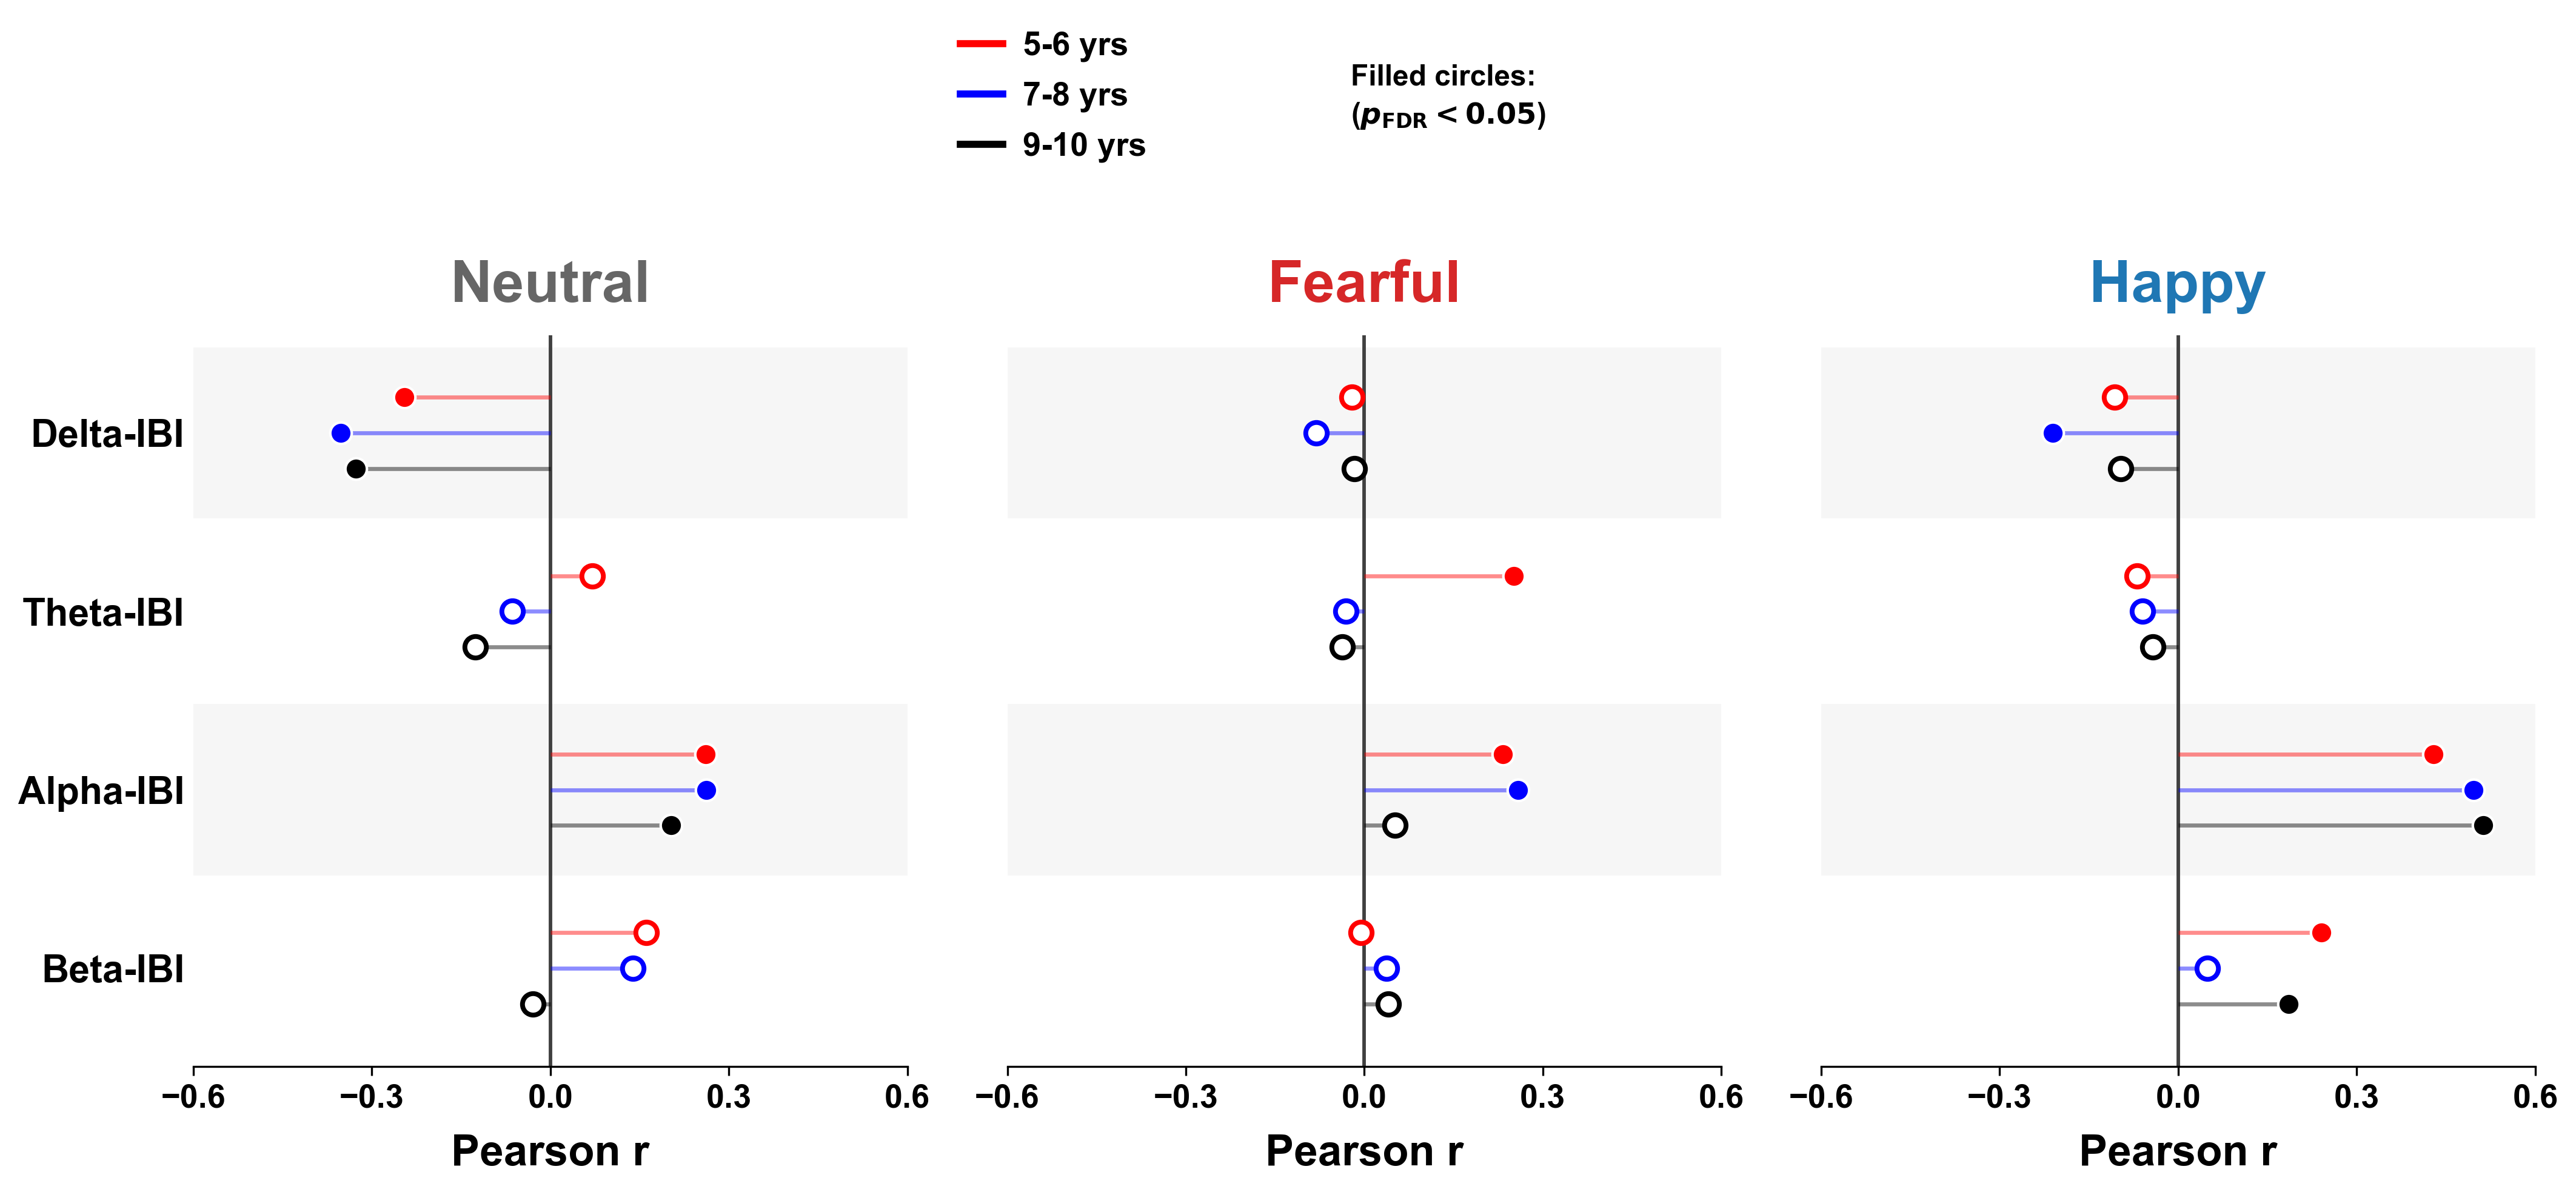

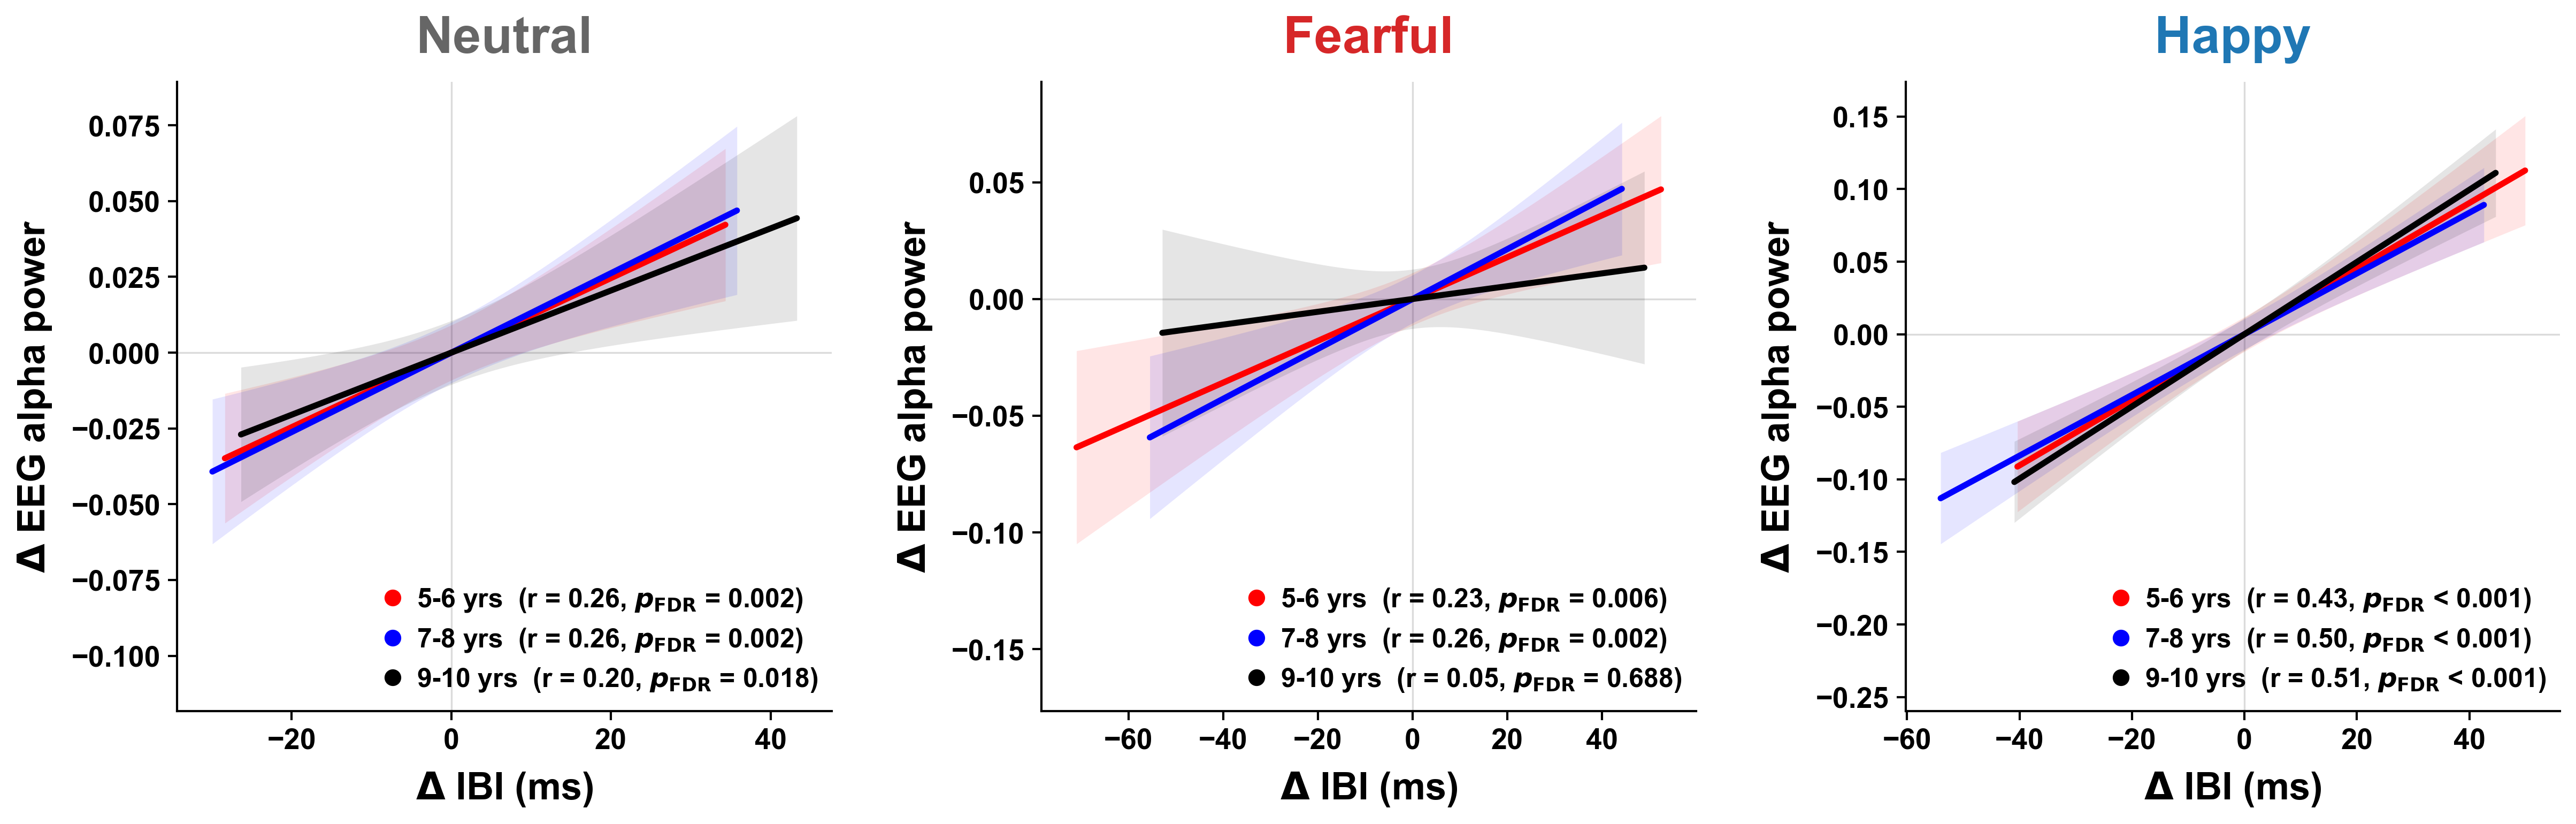

In [9]:
with LOG.step("Figure 2"):
    figure_files = [FIGURE_DIR / name for name in [
        "Figure_2a_eeg_ibi_correlations.png", "Figure_2b_alpha_ibi_regression.png",
    ]]
    figure_sources = [
        RESULT_DIR / "group_mean_correlations.csv",
        RESULT_DIR / "group_mean_timeseries.csv",
        COR / "plotting/plot_figure_2_eeg_ibi_correlations.py",
        COR / "config/correlation_config.py",
    ]
    redraw = RECOMPUTE or "Figure 2" in UPDATED_FIGURES or any(
        cache_policy.figure_needs_update(path, figure_sources) for path in figure_files
    )
    if not cache_policy.use_cached_results(
        figure_files, recompute=redraw, label="Figure 2", log=LOG,
    ):
        with mpl.rc_context(mpl.rcParamsDefault):
            figure_2.plot_figure_2a(RESULT_DIR, FIGURE_DIR)
            figure_2.plot_figure_2b(RESULT_DIR, FIGURE_DIR)
        UPDATED_FIGURES.discard("Figure 2")
    for figure_file in figure_files:
        display(Image(filename=str(figure_file), width=1100))
        LOG.write(f"Figure: {figure_file}")


## 5. Draw or display Figure S2

Show correlations for the frontal, central and posterior regions. Filled circles
use the saved frontal 36-test and central/posterior 72-test FDR families.

Use the same reuse/recompute choice as Figure 2. The figure is displayed below
and saved to `results/SI/Figure_S2_eeg_ibi_correlations.png`.


Figure S2: recomputing and replacing saved results.
Saved: results/SI/Figure_S2_eeg_ibi_correlations.png


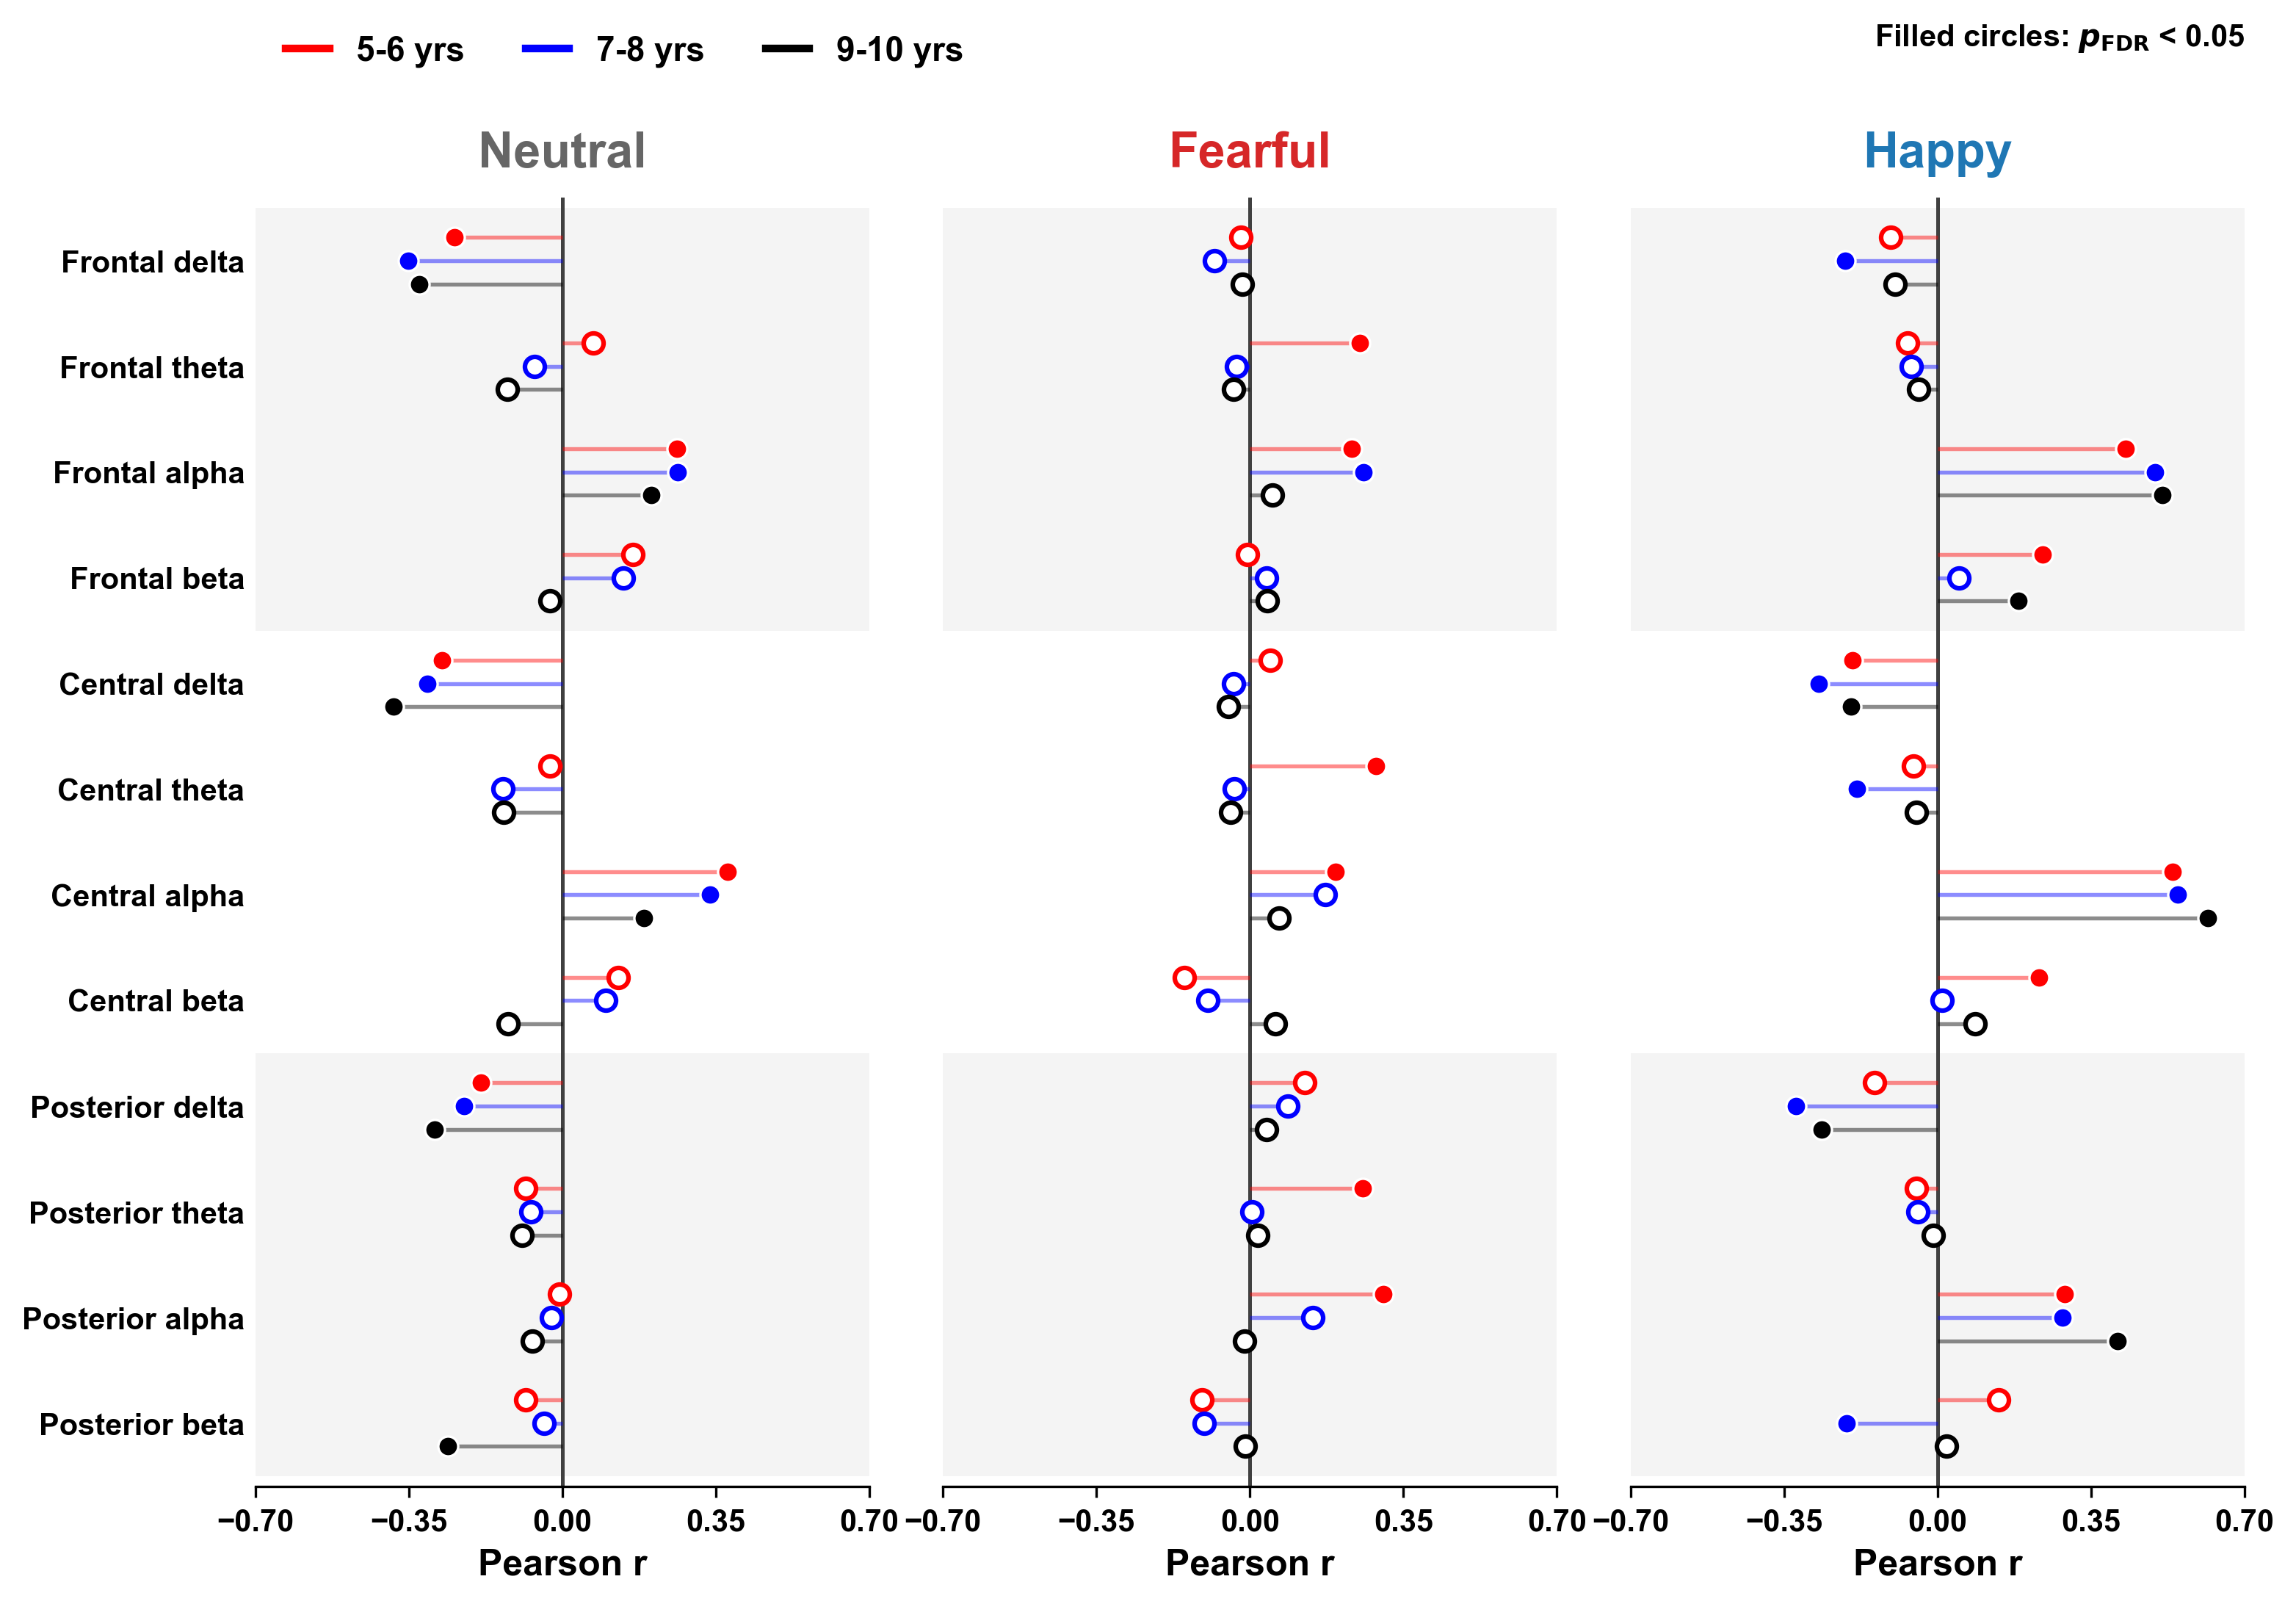

Correlation tables: 03_correlation/cache
Figure 2: results/Main
Figure S2: results/SI/Figure_S2_eeg_ibi_correlations.png
Run log: 03_correlation/logs/20261030_224122.log


In [11]:
with LOG.step("Figure S2"):
    figure_file = SI_DIR / "Figure_S2_eeg_ibi_correlations.png"
    figure_sources = [
        RESULT_DIR / "group_mean_correlations.csv",
        COR / "plotting/plot_figure_s2_eeg_ibi_correlations.py",
        COR / "plotting/plot_figure_2_eeg_ibi_correlations.py",
        COR / "config/correlation_config.py",
    ]
    redraw = RECOMPUTE or "Figure S2" in UPDATED_FIGURES or cache_policy.figure_needs_update(figure_file, figure_sources)
    if not cache_policy.use_cached_results(
        [figure_file], recompute=redraw, label="Figure S2", log=LOG,
    ):
        with mpl.rc_context(mpl.rcParamsDefault):
            figure_file = draw_figure_s2(RESULT_DIR, SI_DIR)
        UPDATED_FIGURES.discard("Figure S2")
    display(Image(filename=str(figure_file), width=1000))
    LOG.write(f"Figure: {figure_file}")

print("Correlation tables:", LOG.display(RESULT_DIR))
print("Figure 2:", LOG.display(FIGURE_DIR))
print("Figure S2:", LOG.display(figure_file))
print("Run log:", LOG.display(LOG.path))


## Further manuscript analyses

The analysis order is **eliciting → correlation → HEP → dBHI**. The remaining
analysis entries are:

| Analysis | What it examines | Outputs |
|---|---|---|
| [HEP](../04_HEP/run_hep.ipynb) | Heartbeat-locked EEG responses and their age effects | Figure 3; Table S3 |
| [dBHI](../05_dBHI/run_dbhi.ipynb) | Directional brain–heart coupling, age prediction and intensity contrasts | Figures 4–5; Figures S3–S7; Tables S4–S6 |

These are separate analyses of the supplied cohort data; each notebook describes
its own inputs and steps.
